In [15]:
import os
import re
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from sklearn.preprocessing import LabelEncoder

import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [16]:
DATA_PATH = "/kaggle/input/datasets/rtatman/deceptive-opinion-spam-corpus/deceptive-opinion.csv"

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(1600, 5)


,deceptive,hotel,polarity,source,text
0,truthful,conrad,positive,TripAdvisor,We stayed for a one night getaway with family ...
1,truthful,hyatt,positive,TripAdvisor,Triple A rate with upgrade to view room was le...
2,truthful,hyatt,positive,TripAdvisor,This comes a little late as I'm finally catchi...
3,truthful,omni,positive,TripAdvisor,The Omni Chicago really delivers on all fronts...
4,truthful,hyatt,positive,TripAdvisor,I asked for a high floor away from the elevato...


In [17]:
# OPSPAM columns typically: deceptive, hotel, polarity, source, text
print(df.columns.tolist())
print(df['deceptive'].value_counts())

# Explicit mapping — do NOT rely on LabelEncoder's alphabetical ordering
label_map = {'truthful': 0, 'deceptive': 1}
inverse_label_map = {0: 'truthful', 1: 'deceptive'}

df['label'] = df['deceptive'].map(label_map)

print("\nLabel mapping:", label_map)
print("\nLabel distribution:\n", df['label'].value_counts())

df[['text', 'deceptive', 'label']].sample(5)

['deceptive', 'hotel', 'polarity', 'source', 'text']
deceptive
truthful     800
deceptive    800
Name: count, dtype: int64

Label mapping: {'truthful': 0, 'deceptive': 1}

Label distribution:
 label
0    800
1    800
Name: count, dtype: int64


,text,deceptive,label
526,This is the hotel for the discriminating busin...,deceptive,1
354,"What a wonderful experience, super great, help...",truthful,0
168,I stayed at the Talbott twice in the last few ...,truthful,0
135,My boyfriend and I were amazed by the breathta...,truthful,0
937,"Rude, rude, rude! We stayed here on July 4th w...",truthful,0


In [18]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)   # remove punctuation/special chars
    text = re.sub(r'\s+', ' ', text).strip()   # collapse whitespace
    return text

df['clean_text'] = df['text'].apply(clean_text)
df[['text', 'clean_text']].sample(3)

,text,clean_text
248,I believe I can not describe how amazing was o...,i believe i can not describe how amazing was o...
927,The elevator system was impossible. It seems t...,the elevator system was impossible it seems th...
602,At first my husband and I were really excited ...,at first my husband and i were really excited ...


In [19]:
# First split off test set, then split remaining into train/val
train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df['label'], random_state=SEED
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.15, stratify=train_val_df['label'], random_state=SEED
)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("Train label balance:\n", train_df['label'].value_counts(normalize=True))

Train: 1156 | Val: 204 | Test: 240
Train label balance:
 label
1    0.5
0    0.5
Name: proportion, dtype: float64


In [20]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),      # unigrams + bigrams, matches Ott et al. methodology
    max_features=5000,
    min_df=2,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(train_df['clean_text']).toarray()
X_val = vectorizer.transform(val_df['clean_text']).toarray()
X_test = vectorizer.transform(test_df['clean_text']).toarray()

y_train = train_df['label'].values
y_val = val_df['label'].values
y_test = test_df['label'].values

print(f"Feature dimension: {X_train.shape[1]}")

Feature dimension: 5000


In [21]:
class ReviewDataset(Dataset):
    def __init__(self, features, labels):
        self.X = torch.tensor(features, dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = ReviewDataset(X_train, y_train)
val_dataset = ReviewDataset(X_val, y_val)
test_dataset = ReviewDataset(X_test, y_test)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [22]:
class FraudReviewClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim // 2, 1)   # raw logit, sigmoid applied in loss/eval
        )

    def forward(self, x):
        return self.net(x).squeeze(1)

model = FraudReviewClassifier(input_dim=X_train.shape[1]).to(device)
print(model)

FraudReviewClassifier(
  (net): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [23]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

EPOCHS = 50
best_val_loss = float('inf')
patience_counter = 0
PATIENCE = 7

history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    # --- Train ---
    model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * X_batch.size(0)
    train_loss /= len(train_dataset)

    # --- Validate ---
    model.eval()
    val_loss = 0.0
    correct = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            val_loss += loss.item() * X_batch.size(0)
            preds = (torch.sigmoid(logits) > 0.5).float()
            correct += (preds == y_batch).sum().item()
    val_loss /= len(val_dataset)
    val_acc = correct / len(val_dataset)

    scheduler.step(val_loss)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # Early stopping + checkpoint best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), "best_fraud_model.pth")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("\nTraining complete. Best val loss:", best_val_loss)

Epoch 01/50 | Train Loss: 0.4981 | Val Loss: 0.6218 | Val Acc: 0.8578
Epoch 02/50 | Train Loss: 0.1439 | Val Loss: 0.3203 | Val Acc: 0.8725
Epoch 03/50 | Train Loss: 0.0524 | Val Loss: 0.2469 | Val Acc: 0.8922
Epoch 04/50 | Train Loss: 0.0285 | Val Loss: 0.2496 | Val Acc: 0.8725
Epoch 05/50 | Train Loss: 0.0162 | Val Loss: 0.2511 | Val Acc: 0.8971
Epoch 06/50 | Train Loss: 0.0118 | Val Loss: 0.2476 | Val Acc: 0.8922
Epoch 07/50 | Train Loss: 0.0156 | Val Loss: 0.2684 | Val Acc: 0.8676
Epoch 08/50 | Train Loss: 0.0163 | Val Loss: 0.2549 | Val Acc: 0.8873
Epoch 09/50 | Train Loss: 0.0062 | Val Loss: 0.2640 | Val Acc: 0.8873
Epoch 10/50 | Train Loss: 0.0062 | Val Loss: 0.2754 | Val Acc: 0.8922
Early stopping at epoch 10

Training complete. Best val loss: 0.2468893983784844


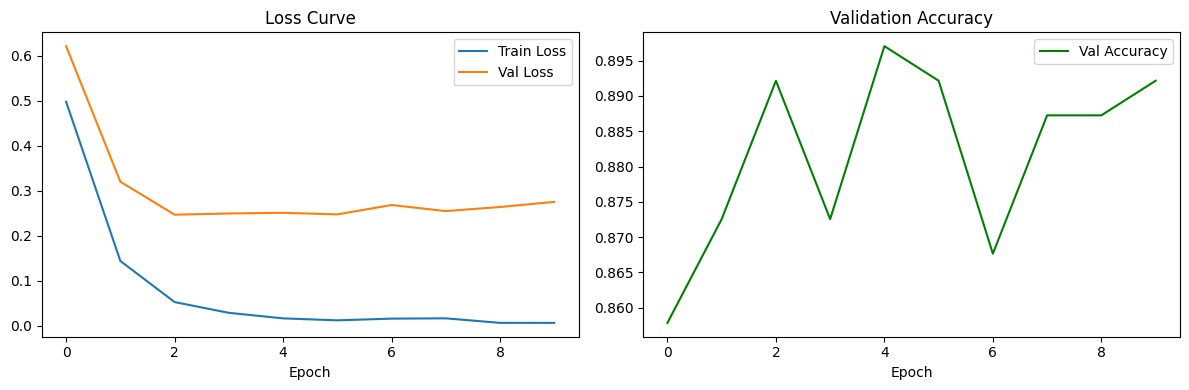

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_title('Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history['val_acc'], label='Val Accuracy', color='green')
axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

In [25]:
model.load_state_dict(torch.load("best_fraud_model.pth"))
model.eval()

all_preds, all_probs, all_labels = [], [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        logits = model(X_batch)
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs > 0.5).astype(int)

        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(y_batch.numpy())

all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

# --- Metrics ---
acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)
roc_auc = roc_auc_score(all_labels, all_probs)

print("=== Test Set Evaluation ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=['truthful', 'deceptive']))

=== Test Set Evaluation ===
Accuracy : 0.8917
Precision: 0.8790
Recall   : 0.9083
F1 Score : 0.8934
ROC-AUC  : 0.9555

Classification Report:

              precision    recall  f1-score   support

    truthful       0.91      0.88      0.89       120
   deceptive       0.88      0.91      0.89       120

    accuracy                           0.89       240
   macro avg       0.89      0.89      0.89       240
weighted avg       0.89      0.89      0.89       240



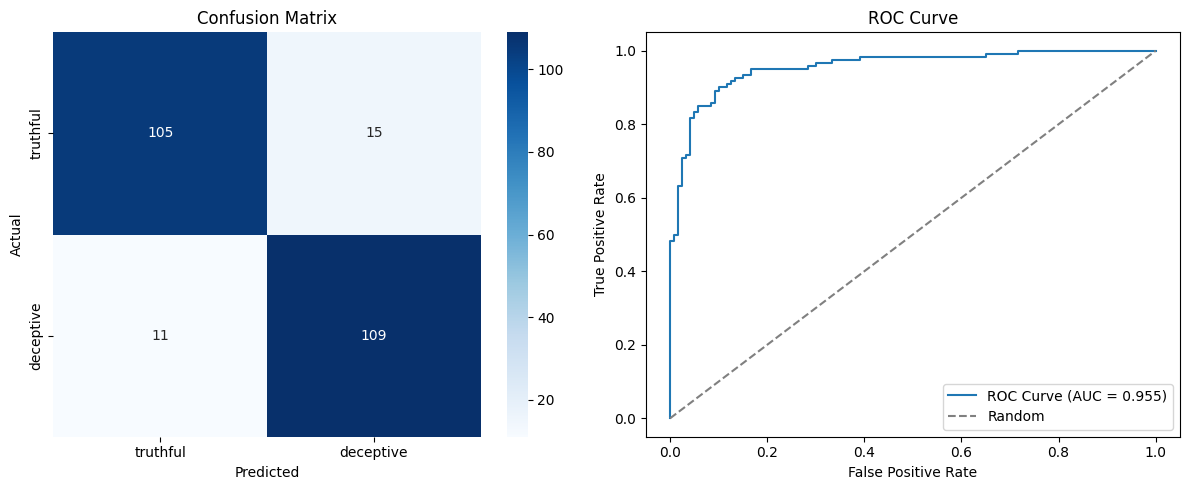

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['truthful', 'deceptive'], yticklabels=['truthful', 'deceptive'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC Curve
fpr, tpr, _ = roc_curve(all_labels, all_probs)
axes[1].plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

In [27]:
# label_encoder no longer needed — label_map is fixed and explicit
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Saved: best_fraud_model.pth, tfidf_vectorizer.pkl")
print("Label mapping (hardcoded, no file needed):", label_map)

Saved: best_fraud_model.pth, tfidf_vectorizer.pkl
Label mapping (hardcoded, no file needed): {'truthful': 0, 'deceptive': 1}


In [28]:
def predict_review(review_text, model, vectorizer, device, threshold=0.5):
    model.eval()
    cleaned = clean_text(review_text)
    features = vectorizer.transform([cleaned]).toarray()
    features_tensor = torch.tensor(features, dtype=torch.float32).to(device)

    with torch.no_grad():
        logit = model(features_tensor)
        prob = torch.sigmoid(logit).item()   # prob of class 1 = deceptive

    pred_label = "deceptive" if prob > threshold else "truthful"
    confidence = prob if pred_label == "deceptive" else 1 - prob

    return pred_label, confidence, prob


# --- Interactive loop ---
print("Fraud Review Detector — type 'exit' to stop\n")

while True:
    user_review = input("Enter a review to check: ")
    if user_review.strip().lower() == "exit":
        print("Exiting.")
        break
    if not user_review.strip():
        print("Please enter some text.\n")
        continue

    label, confidence, raw_prob = predict_review(
        user_review, model, vectorizer, device
    )

    print(f"\nPrediction : {label.upper()}")
    print(f"Confidence : {confidence*100:.2f}%")
    print(f"Raw probability of deception: {raw_prob:.4f}\n")
    print("-" * 50)

Fraud Review Detector — type 'exit' to stop



Enter a review to check:  The room was clean but smaller than expected for the price. Check-in took almost 20 minutes because only one staff member was at the front desk. Breakfast buffet was decent, mostly local dishes, coffee was weak though. Location is good, walking distance to the beach but a bit far from restaurants.



Prediction : TRUTHFUL
Confidence : 99.19%
Raw probability of deception: 0.0081

--------------------------------------------------


Enter a review to check:  Stayed here for a business trip, 2 nights. Wifi kept dropping in the evenings which was annoying since I needed it for work calls. Bed was comfortable, AC worked fine. Would book again if the wifi issue gets fixed.



Prediction : TRUTHFUL
Confidence : 60.52%
Raw probability of deception: 0.3948

--------------------------------------------------


...


Prediction : DECEPTIVE
Confidence : 54.86%
Raw probability of deception: 0.5486

--------------------------------------------------


Enter a review to check:  I honestly wasn't expecting much but Galle Fort completely blew me away in every possible way. The moment we entered the fort walls every single person we met was incredibly friendly and every shop had the most amazing items imaginable.



Prediction : DECEPTIVE
Confidence : 86.76%
Raw probability of deception: 0.8676

--------------------------------------------------


Enter a review to check:  exit


Exiting.


In [29]:
import json
import shutil
from pathlib import Path

# ============================================================
# 1. Create deployment folder structure
# ============================================================
DEPLOY_DIR = Path("/kaggle/working/fraud_review_detector_deployment")
DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

print(f"Deployment folder created at: {DEPLOY_DIR}")

# ============================================================
# 2. Save PyTorch model weights (.pth) — raw tensor state dict
# ============================================================
model.load_state_dict(torch.load("best_fraud_model.pth"))  # ensure best weights loaded
torch.save(model.state_dict(), DEPLOY_DIR / "fraud_model.pth")

# ============================================================
# 3. Save TF-IDF vectorizer (.pkl) — needed to transform raw text at inference
# ============================================================
joblib.dump(vectorizer, DEPLOY_DIR / "tfidf_vectorizer.pkl")

# ============================================================
# 4. Export model weights as JSON (portable, human-readable format)
#    Converts every tensor in the state dict to nested lists
# ============================================================
state_dict = model.state_dict()
weights_json = {}

for param_name, tensor in state_dict.items():
    weights_json[param_name] = tensor.cpu().numpy().tolist()

with open(DEPLOY_DIR / "model_weights.json", "w") as f:
    json.dump(weights_json, f)

print(f"JSON weights file size: {(DEPLOY_DIR / 'model_weights.json').stat().st_size / 1e6:.2f} MB")

# ============================================================
# 5. Export model architecture + training metadata as JSON
#    This lets anyone rebuild the exact model + preprocessing without the notebook
# ============================================================
metadata = {
    "model_name": "FraudReviewClassifier",
    "framework": "PyTorch",
    "architecture": {
        "input_dim": X_train.shape[1],
        "hidden_dim": 256,
        "dropout": 0.4,
        "layers": [
            "Linear(input_dim, 256) -> BatchNorm1d -> ReLU -> Dropout",
            "Linear(256, 128) -> BatchNorm1d -> ReLU -> Dropout",
            "Linear(128, 1)  # raw logit output"
        ]
    },
    "label_mapping": label_map,                     # {'truthful': 0, 'deceptive': 1}
    "inverse_label_mapping": inverse_label_map,      # {0: 'truthful', 1: 'deceptive'}
    "prediction_threshold": 0.5,
    "vectorizer": {
        "type": "TfidfVectorizer",
        "ngram_range": [1, 2],
        "max_features": 5000,
        "min_df": 2,
        "sublinear_tf": True
    },
    "training_config": {
        "optimizer": "AdamW",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "loss_function": "BCEWithLogitsLoss",
        "batch_size": BATCH_SIZE,
        "epochs_trained": len(history['train_loss']),
        "early_stopping_patience": PATIENCE
    },
    "evaluation_metrics": {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "roc_auc": float(roc_auc)
    },
    "preprocessing": {
        "text_cleaning": "lowercase, remove punctuation/special chars, collapse whitespace"
    },
    "dataset_source": "Deceptive Opinion Spam Corpus (Ott et al., Cornell University)",
    "pytorch_version": torch.__version__,
    "sklearn_input_type": "dense TF-IDF array (toarray())"
}

with open(DEPLOY_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved model_metadata.json")

# ============================================================
# 6. Save a standalone inference script (so the folder is self-contained)
# ============================================================
inference_script = '''
import json
import re
import joblib
import torch
import torch.nn as nn

class FraudReviewClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\\s]", " ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text


def load_model(metadata_path="model_metadata.json",
                vectorizer_path="tfidf_vectorizer.pkl",
                weights_path="fraud_model.pth"):
    with open(metadata_path) as f:
        metadata = json.load(f)

    vectorizer = joblib.load(vectorizer_path)

    model = FraudReviewClassifier(
        input_dim=metadata["architecture"]["input_dim"],
        hidden_dim=metadata["architecture"]["hidden_dim"],
        dropout=metadata["architecture"]["dropout"]
    )
    model.load_state_dict(torch.load(weights_path, map_location="cpu"))
    model.eval()

    return model, vectorizer, metadata


def predict(review_text, model, vectorizer, metadata):
    cleaned = clean_text(review_text)
    features = vectorizer.transform([cleaned]).toarray()
    features_tensor = torch.tensor(features, dtype=torch.float32)

    with torch.no_grad():
        logit = model(features_tensor)
        prob = torch.sigmoid(logit).item()

    threshold = metadata["prediction_threshold"]
    label = "deceptive" if prob > threshold else "truthful"
    confidence = prob if label == "deceptive" else 1 - prob

    return {"label": label, "confidence": confidence, "raw_probability": prob}


if __name__ == "__main__":
    model, vectorizer, metadata = load_model()
    sample = "This hotel is amazing amazing amazing, best ever, 5 stars!!!"
    result = predict(sample, model, vectorizer, metadata)
    print(result)
'''

with open(DEPLOY_DIR / "inference.py", "w") as f:
    f.write(inference_script)

print("Saved inference.py")

# ============================================================
# 7. Save a requirements.txt for deployment reproducibility
# ============================================================
requirements = """torch>=2.0.0
scikit-learn>=1.2.0
joblib>=1.2.0
numpy>=1.23.0
"""
with open(DEPLOY_DIR / "requirements.txt", "w") as f:
    f.write(requirements)

print("Saved requirements.txt")

# ============================================================
# 8. List final folder contents
# ============================================================
print("\n=== Deployment folder contents ===")
for file in sorted(DEPLOY_DIR.iterdir()):
    size_kb = file.stat().st_size / 1024
    print(f"  {file.name:30s} {size_kb:,.1f} KB")

# ============================================================
# 9. Zip the entire folder
# ============================================================
zip_path = "/kaggle/working/fraud_review_detector_deployment"
shutil.make_archive(zip_path, 'zip', DEPLOY_DIR)

zip_file = Path(zip_path + ".zip")
print(f"\nZipped deployment package: {zip_file}")
print(f"Zip file size: {zip_file.stat().st_size / 1e6:.2f} MB")
print("\nDownload this .zip from the Kaggle 'Output' tab on the right panel.")

Deployment folder created at: /kaggle/working/fraud_review_detector_deployment
JSON weights file size: 29.65 MB
Saved model_metadata.json
Saved inference.py
Saved requirements.txt

=== Deployment folder contents ===
  fraud_model.pth                5,141.9 KB
  inference.py                   2.2 KB
  model_metadata.json            1.4 KB
  model_weights.json             28,956.1 KB
  requirements.txt               0.1 KB
  tfidf_vectorizer.pkl           186.8 KB

Zipped deployment package: /kaggle/working/fraud_review_detector_deployment.zip
Zip file size: 17.22 MB

Download this .zip from the Kaggle 'Output' tab on the right panel.
